# Smart Agricultural Bean Classification System

### A Comparative Study of Gaussian, Multinomial, and Bernoulli Naive Bayes Algorithms

## 1. Project Introduction

Agriculture plays a significant role in food production and the
global economy. Identifying and classifying agricultural products
accurately is important for quality control, food processing,
research, and agricultural management.

This project focuses on developing a Machine Learning-based
classification system that identifies different varieties of dry
beans using their physical and morphological characteristics.

The system utilizes the Dry Bean Dataset, which contains numerical
measurements extracted from images of seven different bean varieties.

Three variants of the Naive Bayes classification algorithm will
be implemented and evaluated:

1. Gaussian Naive Bayes (GaussianNB)
2. Multinomial Naive Bayes (MultinomialNB)
3. Bernoulli Naive Bayes (BernoulliNB)

Since these algorithms have different assumptions about input
features, appropriate feature transformations will be applied
before training each model.

### Project Objectives

- Understand and explore the Dry Bean Dataset.
- Perform exploratory data analysis (EDA).
- Prepare numerical features for different Naive Bayes algorithms.
- Implement Gaussian Naive Bayes using continuous features.
- Implement Multinomial Naive Bayes using non-negative
  discretized features.
- Implement Bernoulli Naive Bayes using binary features.
- Evaluate all three models using appropriate classification metrics.
- Compare their performance and identify their strengths
  and limitations.
- Analyze classification errors and model behavior.
- Identify the most suitable Naive Bayes approach for this dataset.

### Research Questions

1. How effectively can Naive Bayes algorithms classify different
   varieties of dry beans?
2. Which Naive Bayes variant performs best on this dataset?
3. How does feature representation affect classification performance?
4. Does discretization improve the performance of MultinomialNB
   and BernoulliNB?
5. Which bean varieties are most frequently misclassified?

### Expected Outcome

A comparative machine learning classification system that
demonstrates the practical differences between three Naive Bayes
algorithms on a real-world agricultural dataset.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

## 2. Dataset Loading and Initial Inspection

The dataset used in this project is the Dry Bean Dataset obtained
from the UCI Machine Learning Repository.

It contains measurements describing the shape, size, and
morphological characteristics of seven different dry bean varieties.

### Dataset Information

- Dataset Name: Dry Bean Dataset
- Total Observations: 13,611
- Input Features: 16 numerical features
- Target Variable: Class
- Classification Type: Multiclass Classification
- Number of Classes: 7

### Target Classes

- BARBUNYA
- BOMBAY
- CALI
- DERMASON
- HOROZ
- SEKER
- SIRA


In [4]:
# Load Dataset
df = pd.read_excel('Dry_Bean_Dataset.xlsx')
df.head(3)

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER


In [5]:
# Dataset dimensions
df.shape

(13611, 17)

In [6]:
# Column names
df.columns

Index(['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength',
       'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent',
       'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2',
       'ShapeFactor3', 'ShapeFactor4', 'Class'],
      dtype='str')

In [7]:
# Dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  str    
dtypes: float64(14), int64(2

In [8]:
# Statistical summary
df.describe()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000
mean,53048.284549,855.283459,320.141867,202.270714,1.583242,0.750895,53768.200206,253.064220,0.749733,0.987143,0.873282,0.799864,0.006564,0.001716,0.643590,0.995063
std,29324.095717,214.289696,85.694186,44.970091,0.246678,0.092002,29774.915817,59.177120,0.049086,0.004660,0.059520,0.061713,0.001128,0.000596,0.098996,0.004366
min,20420.000000,524.736000,183.601165,122.512653,1.024868,0.218951,20684.000000,161.243764,0.555315,0.919246,0.489618,0.640577,0.002778,0.000564,0.410339,0.947687
25%,36328.000000,703.523500,253.303633,175.848170,1.432307,0.715928,36714.500000,215.068003,0.718634,0.985670,0.832096,0.762469,0.005900,0.001154,0.581359,0.993703
50%,44652.000000,794.941000,296.883367,192.431733,1.551124,0.764441,45178.000000,238.438026,0.759859,0.988283,0.883157,0.801277,0.006645,0.001694,0.642044,0.996386
75%,61332.000000,977.213000,376.495012,217.031741,1.707109,0.810466,62294.000000,279.446467,0.786851,0.990013,0.916869,0.834270,0.007271,0.002170,0.696006,0.997883
max,254616.000000,1985.370000,738.860153,460.198497,2.430306,0.911423,263261.000000,569.374358,0.866195,0.994677,0.990685,0.987303,0.010451,0.003665,0.974767,0.999733


## 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the characteristics, distributions, and relationships within the Dry Bean Dataset.

This section investigates the numerical features and target classes before applying machine learning algorithms.


### 3.1 Missing Values

Identify whether any features contain missing values.

### 3.2 Duplicate Observations

Check whether duplicate records exist in the dataset.

### 3.3 Target Class Distribution

Analyze the distribution of the seven bean varieties. This helps identify potential class imbalance.

### 3.4 Numerical Feature Distributions

Visualize the distributions of numerical features using histograms and boxplots.

### 3.5 Feature Correlation

Use a correlation heatmap to investigate relationships between numerical features.

In [9]:
# Missing values
df.isnull().sum()

Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64

In [10]:
# Duplicate records
df.duplicated().sum()

np.int64(68)

In [11]:
df.drop_duplicates(inplace=True)

C:\Users\riazu\AppData\Local\Temp\ipykernel_5252\3006716147.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(inplace=True)


In [12]:
# Check Duplicate records again
df.duplicated().sum()

np.int64(0)

In [13]:
# Target distribution
print("\nClass Distribution:")
df["Class"].value_counts()


Class Distribution:


Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1860
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64

### Target Variable Distribution Analysis

The target variable `Class` contains seven different varieties of dry beans.

The class distribution analysis reveals that the dataset is not perfectly balanced.

DERMASON represents the largest class, containing 3,546 observations, whereas BOMBAY represents the smallest class, containing 522 observations.

This difference indicates the presence of class imbalance.


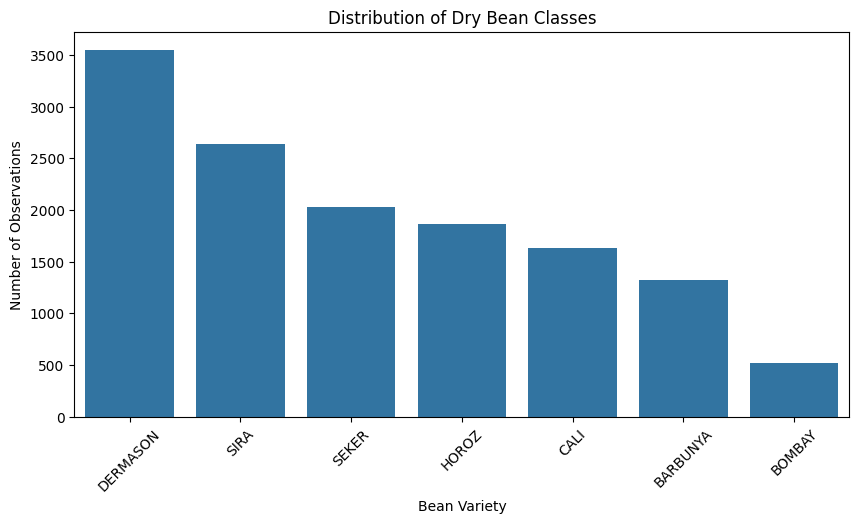

In [14]:
# Class distribution visualization
plt.figure(figsize=(10, 5))
sns.countplot(
    data=df,
    x="Class",
    order=df["Class"].value_counts().index
)
plt.title("Distribution of Dry Bean Classes")
plt.xlabel("Bean Variety")
plt.ylabel("Number of Observations")
plt.xticks(rotation=45)
plt.show()

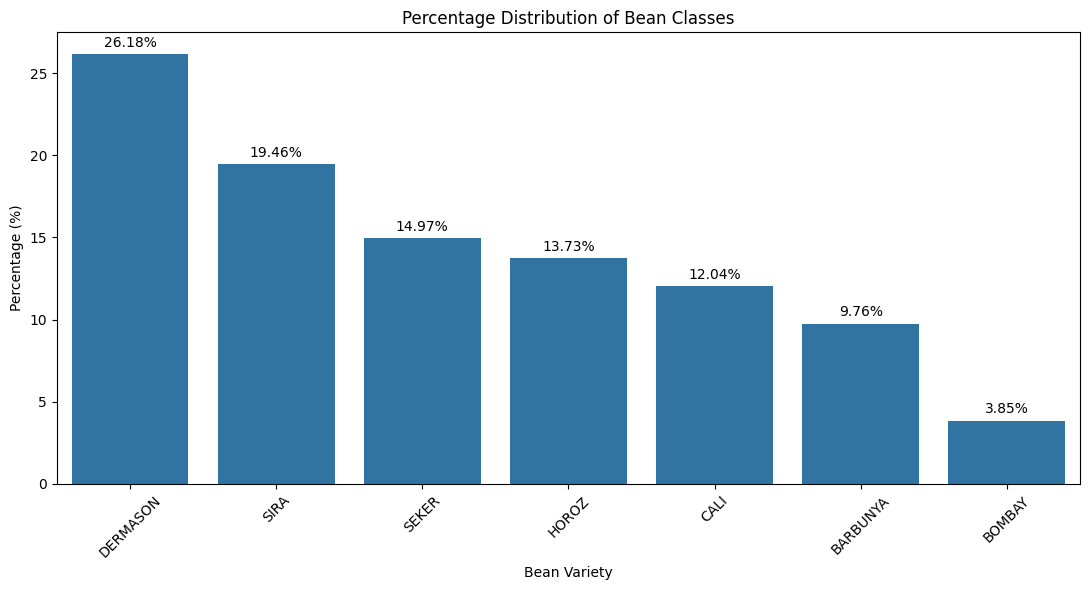

In [15]:
class_percentages = (df["Class"].value_counts(normalize=True).mul(100))

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    x=class_percentages.index,
    y=class_percentages.values
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        padding=3
    )

plt.title("Percentage Distribution of Bean Classes")
plt.xlabel("Bean Variety")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [16]:
# Calculate class distribution
class_counts = df["Class"].value_counts()

# Calculate class percentages
class_percentages = df["Class"].value_counts(normalize=True) * 100

# Create summary table
class_summary = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percentages.round(2)
})

display(class_summary)

,Count,Percentage
Class,,
DERMASON,3546,26.18
SIRA,2636,19.46
SEKER,2027,14.97
HOROZ,1860,13.73
CALI,1630,12.04
BARBUNYA,1322,9.76
BOMBAY,522,3.85


In [17]:
# Calculate imbalance ratio
imbalance_ratio = class_counts.max() / class_counts.min()

print("Imbalance Ratio:", round(imbalance_ratio, 2))

if imbalance_ratio > 1:
    print("The dataset contains class imbalance.")

Imbalance Ratio: 6.79
The dataset contains class imbalance.


### Feature Distribution Across Bean Varieties

After analyzing the target class distribution, the next step is to investigate how numerical feature values vary across the seven bean varieties.

This analysis helps identify differences in the physical and morphological characteristics of the beans.

Boxplots will be used to compare the distributions of selected numerical features across different classes.

The Area feature will be examined first, followed by other important measurements such as Perimeter, MajorAxisLength, MinorAxisLength, and Compactness.

This analysis may reveal differences in feature distributions and potential outliers across classes.

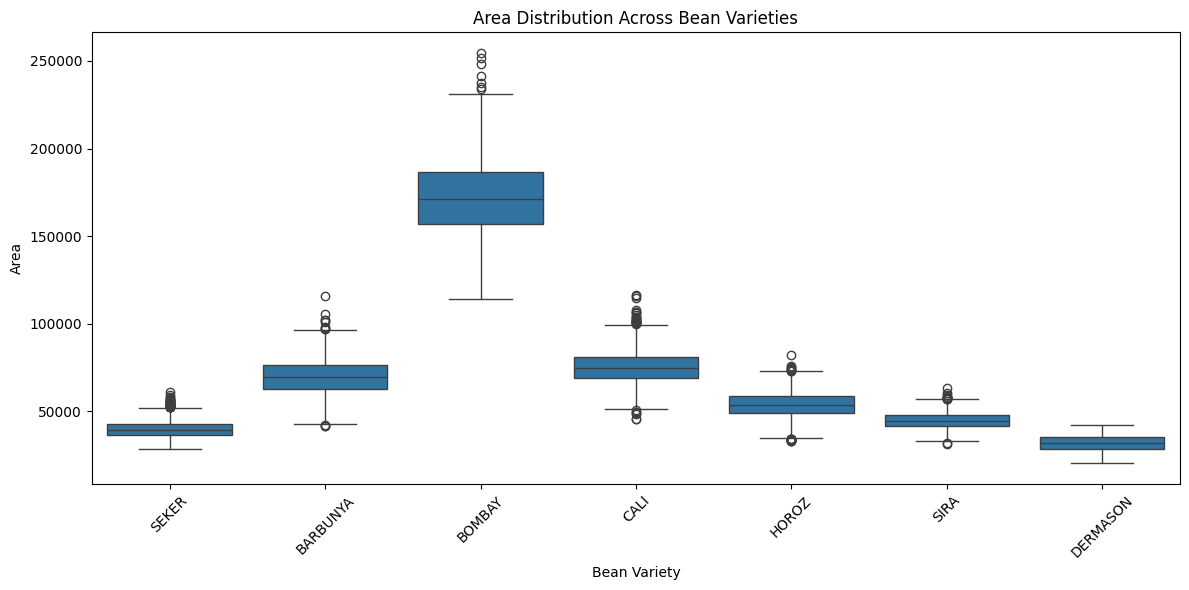

In [18]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="Class",
    y="Area"
)

plt.title("Area Distribution Across Bean Varieties")
plt.xlabel("Bean Variety")
plt.ylabel("Area")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

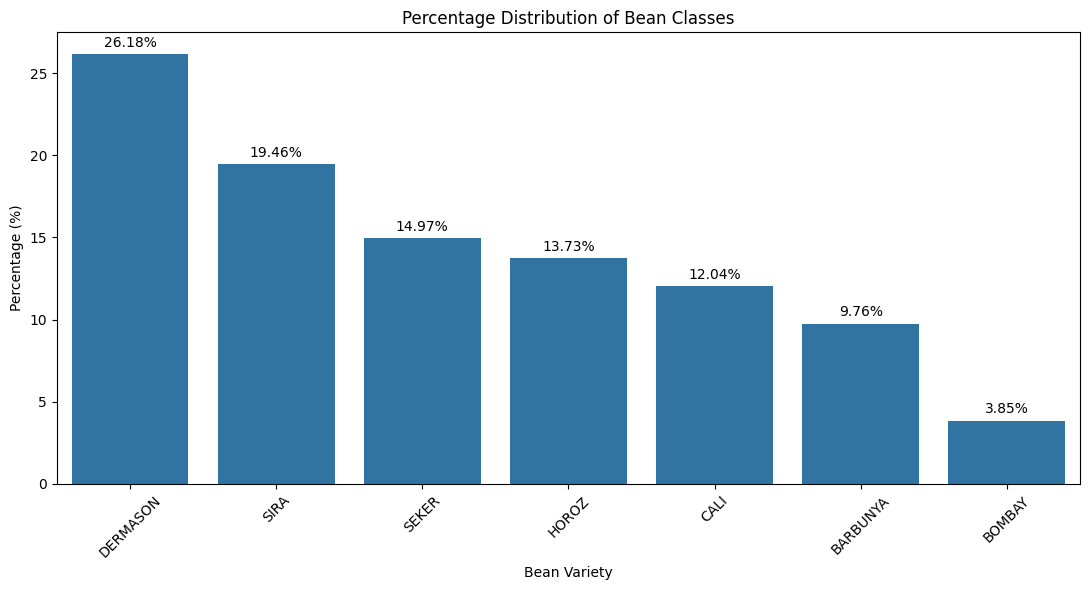

In [19]:
class_percentages = (df["Class"].value_counts(normalize=True).mul(100))

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    x=class_percentages.index,
    y=class_percentages.values
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        padding=3
    )

plt.title("Percentage Distribution of Bean Classes")
plt.xlabel("Bean Variety")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

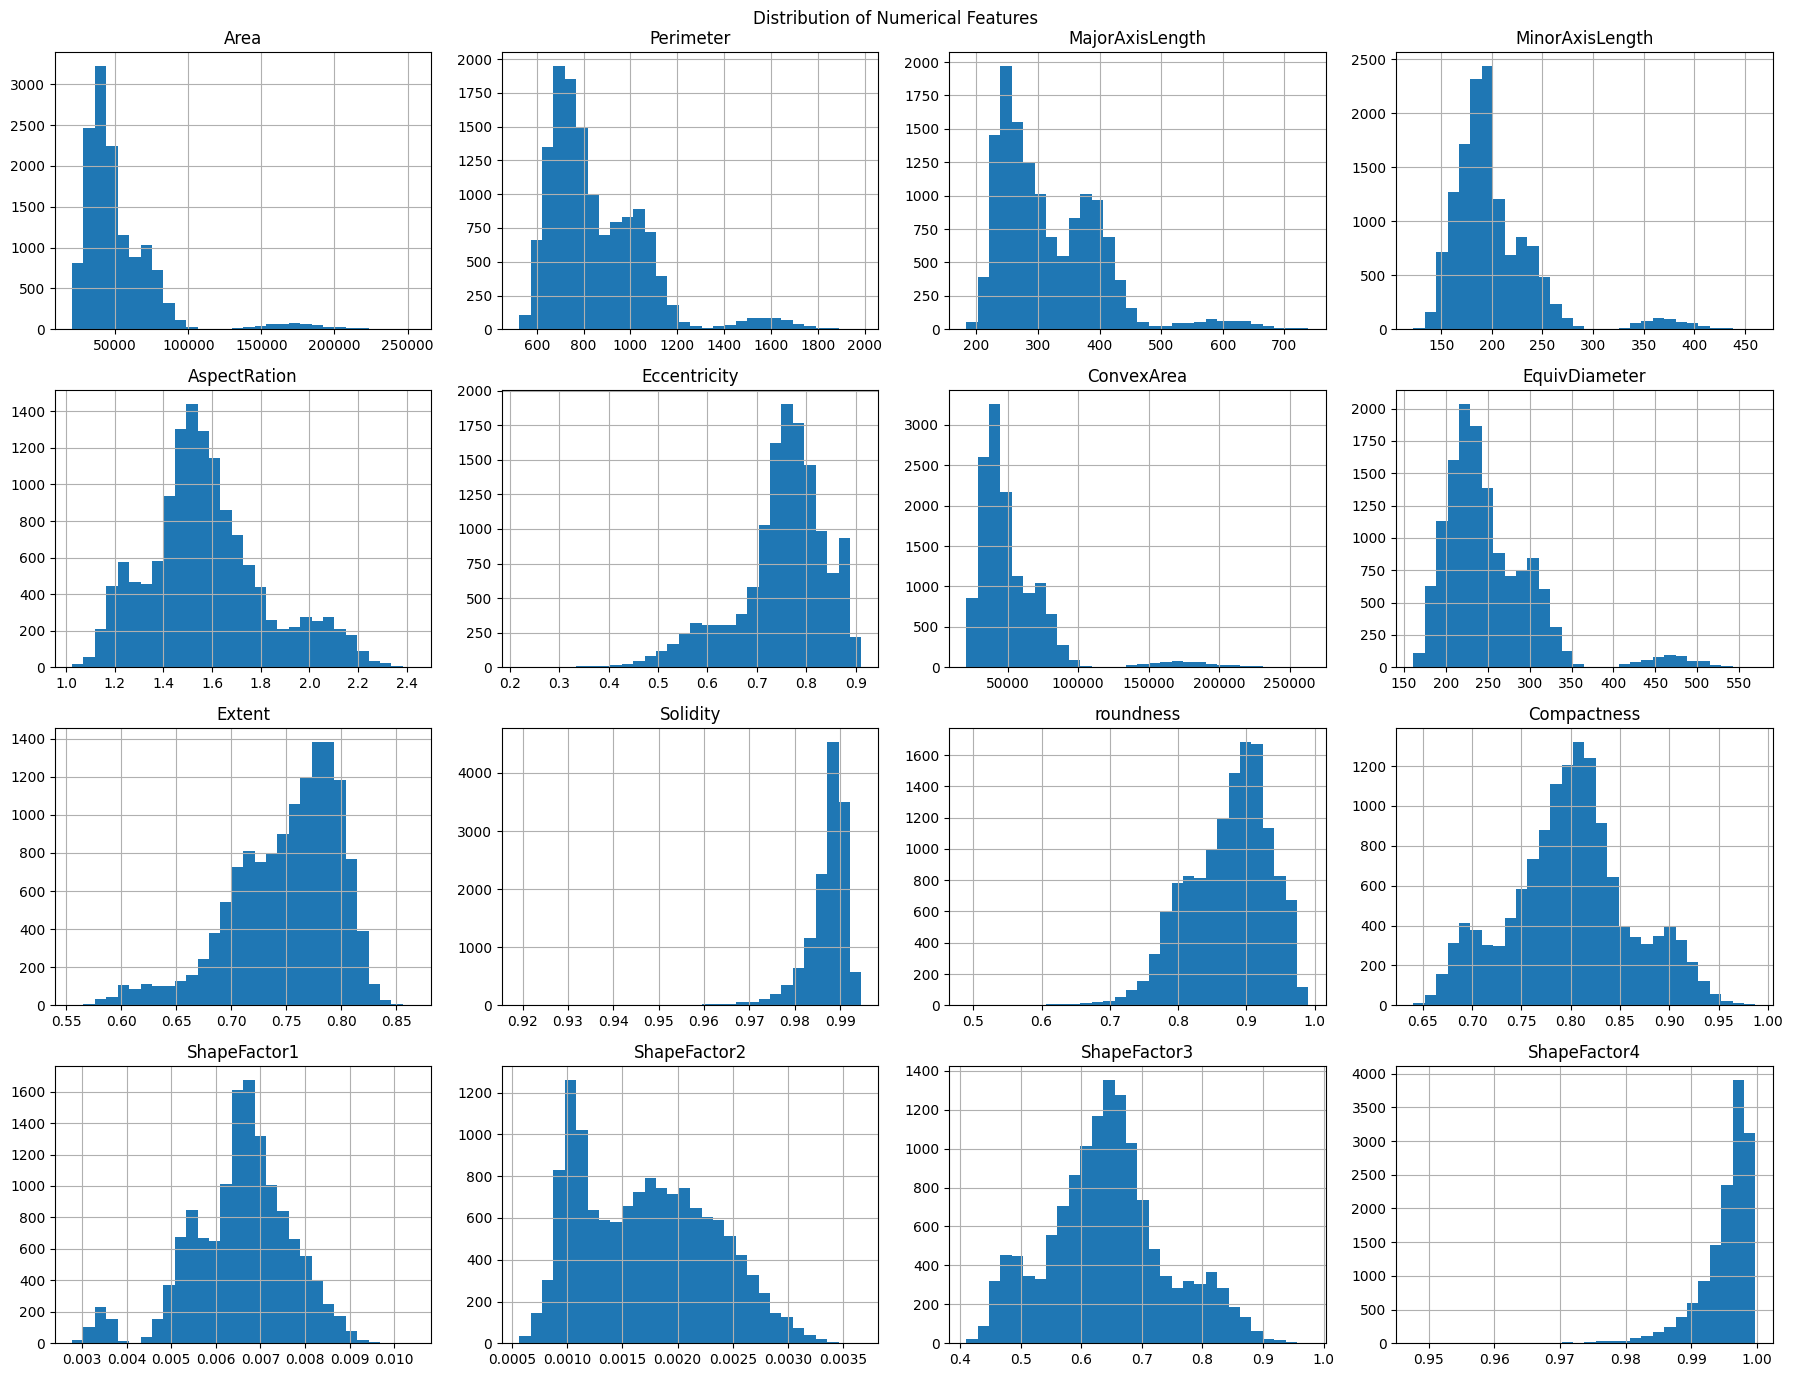

In [20]:
# Feature distributions
numeric_features = df.select_dtypes(
    include=np.number
).columns

df[numeric_features].hist(
    figsize=(18, 14),
    bins=30
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

### Outlier Investigation

Outlier analysis is performed to identify unusually high or low values in the numerical features.

Boxplots and the Interquartile Range (IQR) method will be used to investigate potential outliers.

For each numerical feature:

- Q1 represents the first quartile.
- Q3 represents the third quartile.
- IQR represents the difference between Q3 and Q1.

Observations outside the IQR boundaries will be identified as potential statistical outliers.

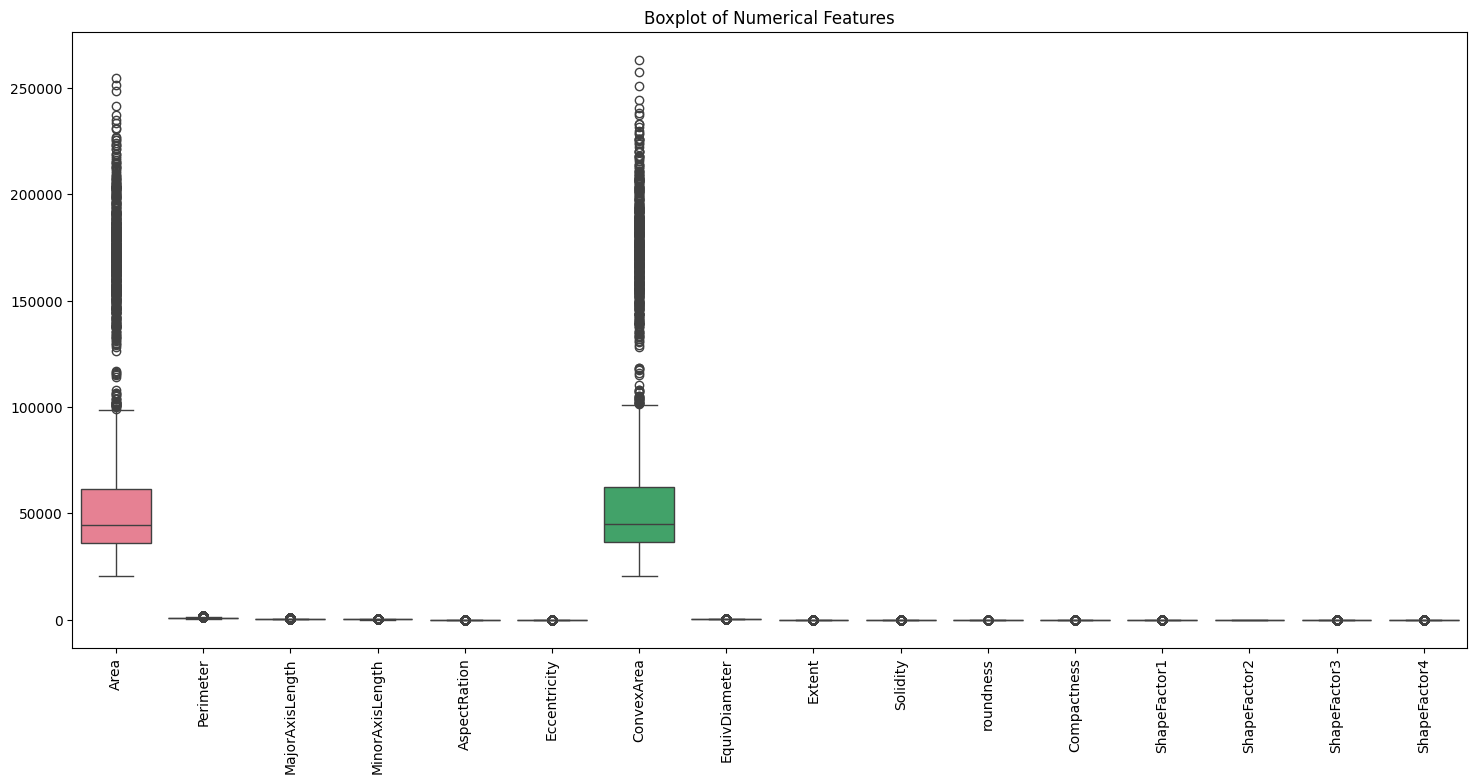

In [21]:
# Boxplots
plt.figure(figsize=(18, 8))

sns.boxplot(data=df[numeric_features])

plt.title("Boxplot of Numerical Features")
plt.xticks(rotation=90)
plt.show()

### Feature Correlation Analysis

Feature correlation analysis is performed to understand the relationships between numerical measurements.

The correlation matrix will be calculated using Pearson correlation coefficients.

A heatmap will be generated to identify strongly correlated feature pairs.

This analysis is particularly relevant to Naive Bayes because the algorithms assume conditional independence between features given the target class.

Highly correlated measurements may indicate overlapping information and may influence model performance.

However, correlation alone does not establish conditional dependence within each class, and correlated features will not automatically be removed.

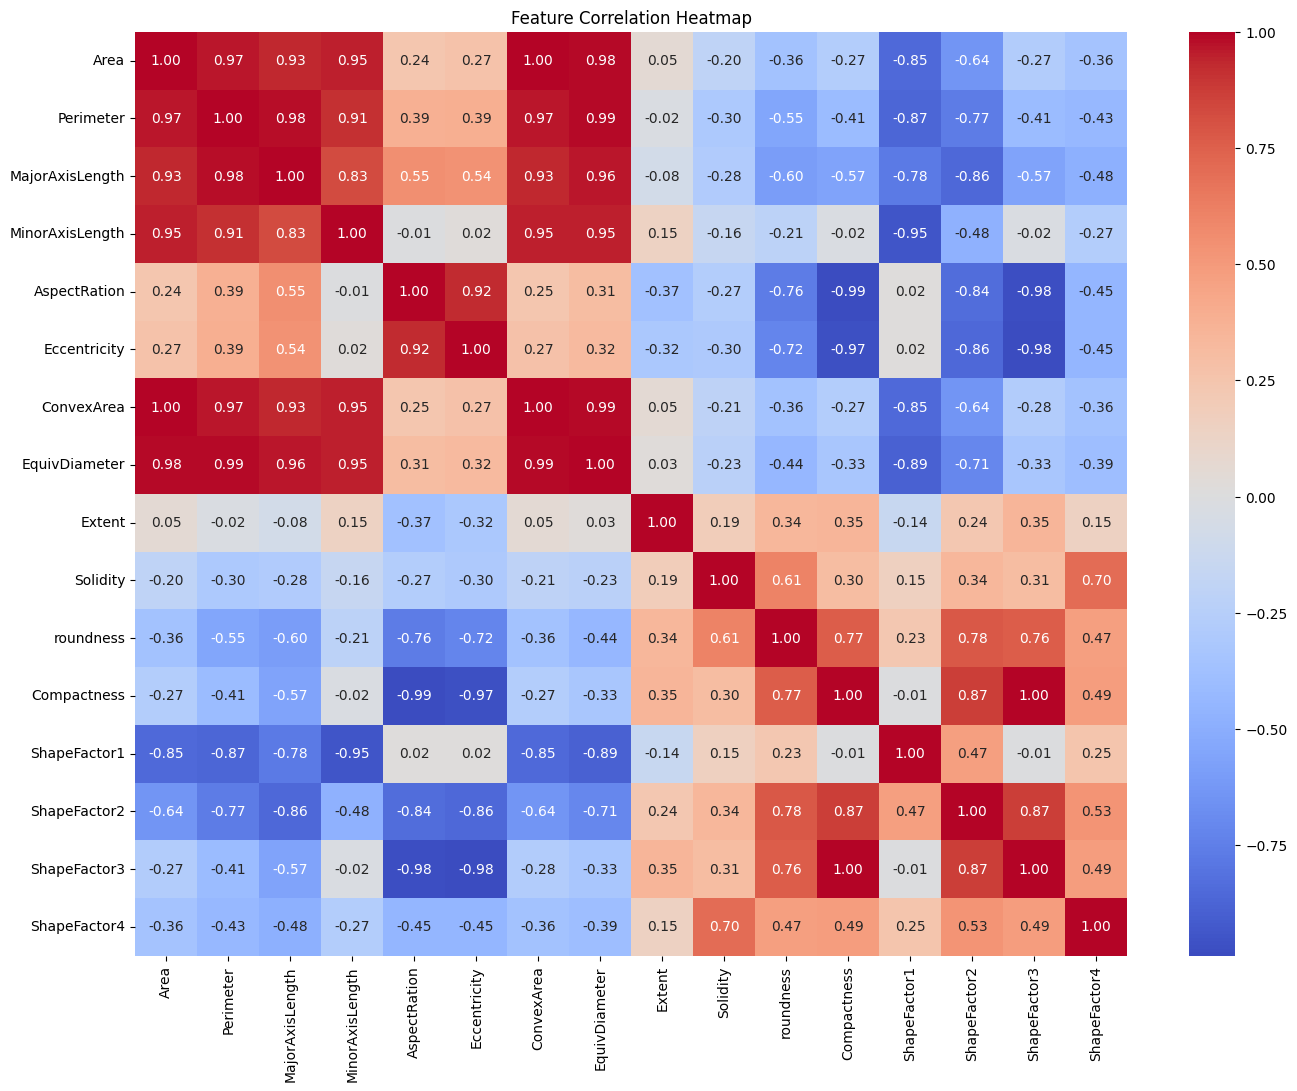

In [22]:
plt.figure(figsize=(16, 12))

sns.heatmap(
    df[numeric_features].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Feature Correlation Heatmap")
plt.show()

### EDA Summary and Key Observations

Exploratory Data Analysis was performed to understand the structure, quality, and characteristics of the Dry Bean Dataset.

The following aspects were investigated:

1. Target Class Distribution:
   The dataset contains seven bean varieties with unequal class frequencies.

2. Class Imbalance:
   DERMASON is the most frequent class, whereas BOMBAY is the least frequent class.

3. Feature Distributions:
   Numerical feature distributions were examined using histograms and boxplots.

4. Missing Values and Duplicates:
   Dataset quality was investigated by checking
   missing observations and 68 duplicate records were removed.

5. Feature Correlation:
   Relationships between numerical features were investigated using a correlation heatmap.

## 4. Data Preprocessing

Data preprocessing is performed to prepare the dataset for machine learning model development.

The following steps will be carried out:

- Verify and handle missing values.
- Investigate duplicate observations.
- Separate independent variables and the target variable.
- Verify numerical feature data types.
- Split the dataset into training and testing subsets.

The original numerical features will be preserved for GaussianNB.

Separate feature transformation will be created for MultinomialNB and BernoulliNB.


In [23]:
# Independent variables
x = df.drop(columns=["Class"])

# Dependent variable
y = df["Class"]

print("X Shape:", x.shape)
print("y Shape:", y.shape)


X Shape: (13543, 16)
y Shape: (13543,)


In [24]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [26]:
sc =  StandardScaler()

# Fit scaler on training data and transform it
X_train_scaled = sc.fit_transform(X_train)

# Transform testing data using the same fitted scaler
X_test_scaled = sc.transform(X_test)

print("Feature Scaling Completed Successfully!")

Feature Scaling Completed Successfully!


In [27]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB

### 5. Training the GaussianNB Model

The GaussianNB classifier will be trained using the standardized training dataset.

During training, the algorithm estimates:

1. The prior probability of each bean variety.
2. The mean of each numerical feature within every class.
3. The variance of each numerical feature within every class.

These probability estimates will be used to classify unseen bean observations.

In [28]:
# Train the GaussianNB model
gnb = GaussianNB()
gnb.fit(X_train_scaled, y_train)

print("GaussianNB Model Trained Successfully!")

GaussianNB Model Trained Successfully!


In [29]:
# Make predictions
y_pred_gaussian = gnb.predict(X_test_scaled)

# Display first 10 predictions
prediction_results = pd.DataFrame({
    "Actual Class": y_test.values[:10],
    "Predicted Class": y_pred_gaussian[:10]
})

display(prediction_results)

,Actual Class,Predicted Class
0,SEKER,SEKER
1,DERMASON,DERMASON
2,DERMASON,DERMASON
3,HOROZ,HOROZ
4,SEKER,SEKER
5,DERMASON,DERMASON
6,DERMASON,DERMASON
7,DERMASON,DERMASON
8,BARBUNYA,BARBUNYA
9,DERMASON,DERMASON


In [30]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

In [31]:
# Calculate evaluation metrics
gaussian_accuracy = accuracy_score(
    y_test,
    y_pred_gaussian
)

gaussian_precision = precision_score(
    y_test,
    y_pred_gaussian,
    average="macro"
)

gaussian_recall = recall_score(
    y_test,
    y_pred_gaussian,
    average="macro"
)

gaussian_macro_f1 = f1_score(
    y_test,
    y_pred_gaussian,
    average="macro"
)

gaussian_weighted_f1 = f1_score(
    y_test,
    y_pred_gaussian,
    average="weighted"
)

# Display results

print("Gaussian Naive Bayes Performance")
print("=" * 40)

print(f"Accuracy:       {gaussian_accuracy:.4f}")
print(f"Macro Precision:{gaussian_precision:.4f}")
print(f"Macro Recall:   {gaussian_recall:.4f}")
print(f"Macro F1-Score: {gaussian_macro_f1:.4f}")
print(f"Weighted F1:    {gaussian_weighted_f1:.4f}")

Gaussian Naive Bayes Performance
Accuracy:       0.8970
Macro Precision:0.9081
Macro Recall:   0.9082
Macro F1-Score: 0.9072
Weighted F1:    0.8972


In [32]:
print(
    classification_report(
        y_test,
        y_pred_gaussian,
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

    BARBUNYA     0.8719    0.7962    0.8323       265
      BOMBAY     1.0000    1.0000    1.0000       104
        CALI     0.8575    0.9233    0.8892       326
    DERMASON     0.9370    0.8604    0.8971       709
       HOROZ     0.9539    0.9462    0.9501       372
       SEKER     0.9223    0.9360    0.9291       406
        SIRA     0.8138    0.8956    0.8528       527

    accuracy                         0.8970      2709
   macro avg     0.9081    0.9082    0.9072      2709
weighted avg     0.8997    0.8970    0.8972      2709



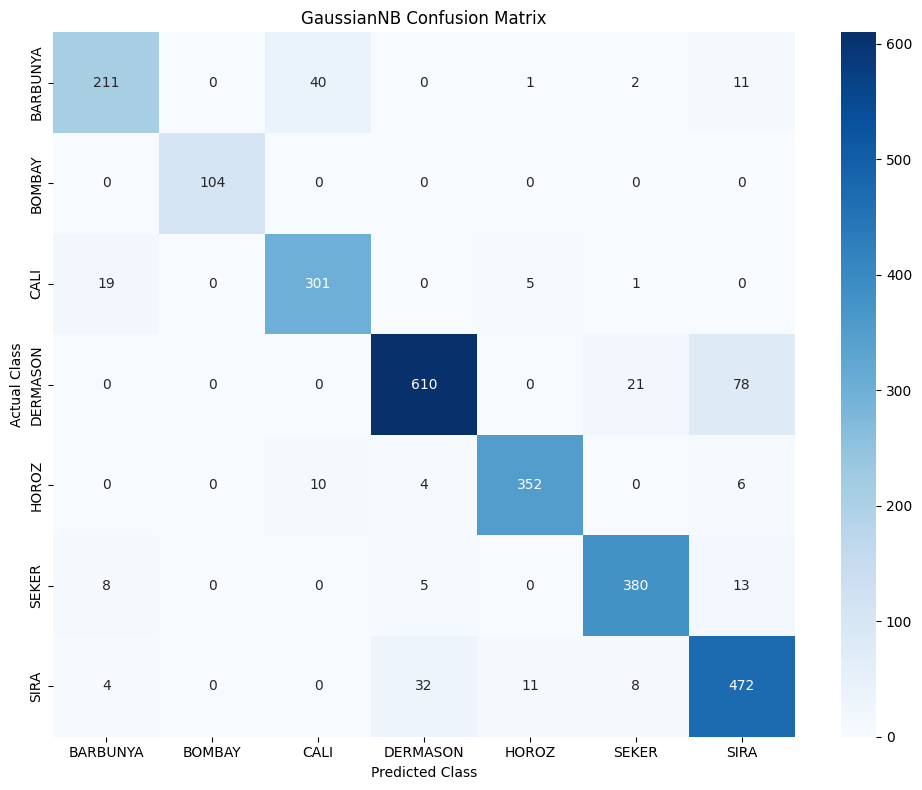

In [33]:
# Generate confusion matrix

cm_gaussian = confusion_matrix(
    y_test,
    y_pred_gaussian,
    labels=gnb.classes_
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_gaussian,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=gnb.classes_,
    yticklabels=gnb.classes_
)

plt.title("GaussianNB Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

,precision,recall,f1-score
BARBUNYA,0.8719,0.7962,0.8323
BOMBAY,1.0000,1.0000,1.0000
CALI,0.8575,0.9233,0.8892
DERMASON,0.9370,0.8604,0.8971
HOROZ,0.9539,0.9462,0.9501
SEKER,0.9223,0.9360,0.9291
SIRA,0.8138,0.8956,0.8528


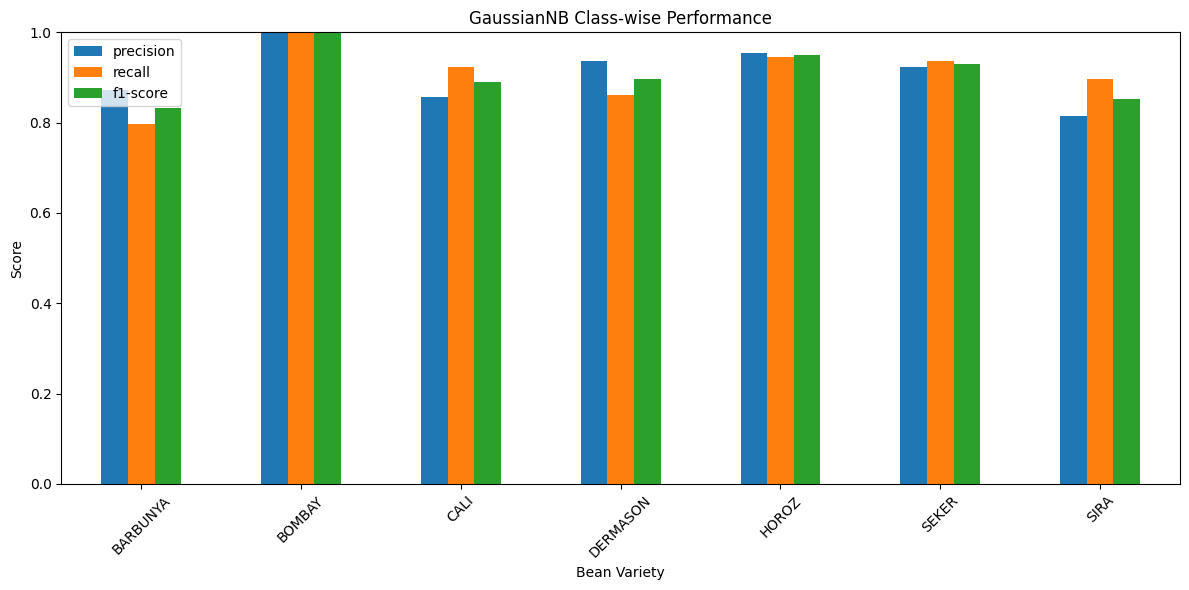

In [34]:
report = classification_report(
    y_test,
    y_pred_gaussian,
    output_dict=True,
    zero_division=0
)

class_metrics = pd.DataFrame(report).T

class_metrics = class_metrics.loc[
    gnb.classes_,
    ["precision", "recall", "f1-score"]
]

display(class_metrics.round(4))

class_metrics.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("GaussianNB Class-wise Performance")
plt.xlabel("Bean Variety")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 6. Multinomial Naive Bayes (MultinomialNB)

### 6.1 Introduction

Multinomial Naive Bayes is a probabilistic classification algorithm based on Bayes' theorem and the Multinomial probability distribution.

It is commonly used in text classification problems, where input features represent word frequencies or discrete event counts.

However, the Dry Bean Dataset contains continuous numerical measurements rather than discrete counts.

To apply MultinomialNB to this dataset, the original continuous features will be transformed into discrete, non-negative feature representations using feature discretization.

### 6.2 Why MultinomialNB?

The dataset contains 16 continuous numerical features describing the physical and morphological properties of dry beans.

These measurements will be divided into discrete intervals using KBinsDiscretizer.

One-hot encoding will then represent each feature's interval as a binary indicator.

This transformation produces non-negative features that can be used by MultinomialNB.

### 6.3 Feature Representation

The 16 original continuous numerical features will be transformed using:

1. KBinsDiscretizer
2. Quantile-based discretization
3. One-hot encoding

Five bins will initially be used for each feature.

Each original feature will therefore be represented by up to five binary indicator columns.

The resulting transformed dataset will contain up to 80 features.

### 6.4 Target Variable

The target variable remains the original Class column containing seven bean varieties.

### 6.5 Model Objective

Train MultinomialNB using discretized bean measurements and compare its classification performance with GaussianNB.

In [47]:
from sklearn.preprocessing import KBinsDiscretizer

In [48]:
X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

### Feature Discretization

MultinomialNB requires non-negative feature representations.

The original Dry Bean Dataset contains continuous numerical measurements, so KBinsDiscretizer will be used to convert them into discrete intervals.

The following configuration will initially be used:

- Number of bins: 5
- Strategy: Quantile
- Encoding: One-hot

Quantile discretization divides each numerical feature into intervals containing approximately equal numbers of training observations.

One-hot encoding converts the resulting intervals into binary indicator features.

For 16 original features and five bins per feature, the transformed dataset can contain up to 80 features.

In [49]:
# Create discretizer

multinomial_discretizer = KBinsDiscretizer(
    n_bins=5,
    encode="onehot-dense",
    strategy="quantile"
)

# Fit and transform training data
X_train_multi = multinomial_discretizer.fit_transform(
    X_train
)

# Transform testing data
X_test_multi = multinomial_discretizer.transform(
    X_test
)

print("Original Training Shape:", X_train.shape)
print("Transformed Training Shape:", X_train_multi.shape)

print("\nOriginal Testing Shape:", X_test.shape)
print("Transformed Testing Shape:", X_test_multi.shape)

Original Training Shape: (10834, 16)
Transformed Training Shape: (10834, 80)

Original Testing Shape: (2709, 16)
Transformed Testing Shape: (2709, 80)


In [50]:
# Convert transformed training data into DataFrame

X_train_multi_df = pd.DataFrame(
    X_train_multi
)

display(X_train_multi_df.head())

,0,1,2,3,4,5,6,7,8,9,...,70,71,72,73,74,75,76,77,78,79
0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
2,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


In [51]:
print("Minimum Value:", X_train_multi.min())
print("Maximum Value:", X_train_multi.max())

print(
    "Contains Negative Values:",
    np.any(X_train_multi < 0)
)

Minimum Value: 0.0
Maximum Value: 1.0
Contains Negative Values: False


In [52]:
multi_feature_names = (
    multinomial_discretizer.get_feature_names_out(
        X_train.columns
    )
)

print("Total Transformed Features:", len(multi_feature_names))

print("\nFirst 20 Transformed Features:")
print(multi_feature_names[:20])

Total Transformed Features: 80

First 20 Transformed Features:
['Area_0.0' 'Area_1.0' 'Area_2.0' 'Area_3.0' 'Area_4.0' 'Perimeter_0.0'
 'Perimeter_1.0' 'Perimeter_2.0' 'Perimeter_3.0' 'Perimeter_4.0'
 'MajorAxisLength_0.0' 'MajorAxisLength_1.0' 'MajorAxisLength_2.0'
 'MajorAxisLength_3.0' 'MajorAxisLength_4.0' 'MinorAxisLength_0.0'
 'MinorAxisLength_1.0' 'MinorAxisLength_2.0' 'MinorAxisLength_3.0'
 'MinorAxisLength_4.0']


### Training the MultinomialNB Model

The MultinomialNB classifier will be trained using the discretized and one-hot encoded training features.

During training, the algorithm estimates:

1. Prior probabilities of the seven bean varieties.
2. Feature probabilities for each class.
3. Smoothed probability estimates using the alpha parameter.

The trained model will use these probability estimates to classify unseen bean observations.

In [53]:
# Create MultinomialNB classifier

mnb = MultinomialNB(
    alpha=1.0,
    fit_prior=True,
    force_alpha=True
)

print("MultinomialNB Model Created Successfully!")

MultinomialNB Model Created Successfully!


In [54]:
# Train MultinomialNB

mnb.fit(
    X_train_multi,
    y_train
)

print("MultinomialNB Model Trained Successfully!")

MultinomialNB Model Trained Successfully!


In [55]:
# Make predictions

y_pred_multinomial = mnb.predict(
    X_test_multi
)

# Display first 10 predictions

multinomial_predictions = pd.DataFrame({
    "Actual Class": y_test.values[:10],
    "Predicted Class": y_pred_multinomial[:10]
})

display(multinomial_predictions)

,Actual Class,Predicted Class
0,SEKER,SEKER
1,DERMASON,DERMASON
2,DERMASON,DERMASON
3,HOROZ,HOROZ
4,SEKER,SEKER
5,DERMASON,DERMASON
6,DERMASON,DERMASON
7,DERMASON,DERMASON
8,BARBUNYA,BARBUNYA
9,DERMASON,DERMASON


In [56]:
# Calculate evaluation metrics

multinomial_accuracy = accuracy_score(
    y_test,
    y_pred_multinomial
)

multinomial_precision = precision_score(
    y_test,
    y_pred_multinomial,
    average="macro",
    zero_division=0
)

multinomial_recall = recall_score(
    y_test,
    y_pred_multinomial,
    average="macro",
    zero_division=0
)

multinomial_macro_f1 = f1_score(
    y_test,
    y_pred_multinomial,
    average="macro",
    zero_division=0
)

multinomial_weighted_f1 = f1_score(
    y_test,
    y_pred_multinomial,
    average="weighted",
    zero_division=0
)

# Display results

print("Multinomial Naive Bayes Performance")
print("=" * 45)

print(f"Accuracy:        {multinomial_accuracy:.4f}")
print(f"Macro Precision: {multinomial_precision:.4f}")
print(f"Macro Recall:    {multinomial_recall:.4f}")
print(f"Macro F1-Score:  {multinomial_macro_f1:.4f}")
print(f"Weighted F1:     {multinomial_weighted_f1:.4f}")

Multinomial Naive Bayes Performance
Accuracy:        0.8568
Macro Precision: 0.8334
Macro Recall:    0.8263
Macro F1-Score:  0.8280
Weighted F1:     0.8568


In [57]:
print(
    classification_report(
        y_test,
        y_pred_multinomial,
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

    BARBUNYA     0.8472    0.7321    0.7854       265
      BOMBAY     0.6915    0.6250    0.6566       104
        CALI     0.7136    0.8558    0.7782       326
    DERMASON     0.9135    0.8787    0.8958       709
       HOROZ     0.9309    0.9409    0.9358       372
       SEKER     0.9069    0.9360    0.9212       406
        SIRA     0.8301    0.8159    0.8230       527

    accuracy                         0.8568      2709
   macro avg     0.8334    0.8263    0.8280      2709
weighted avg     0.8596    0.8568    0.8568      2709



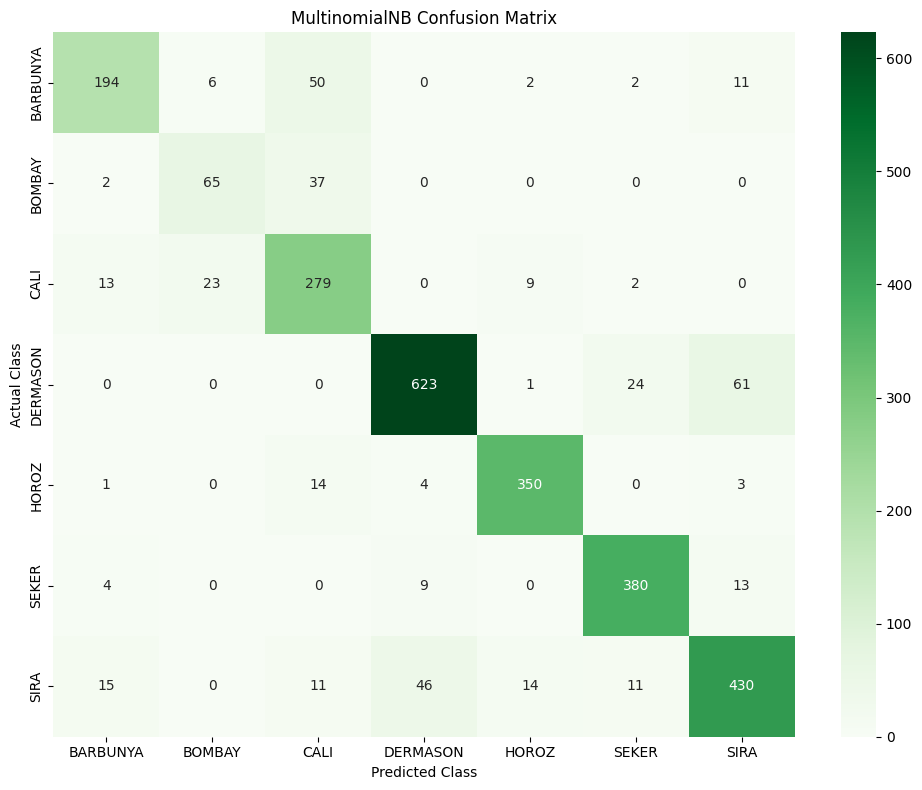

In [58]:
cm_multinomial = confusion_matrix(
    y_test,
    y_pred_multinomial,
    labels=mnb.classes_
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_multinomial,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=mnb.classes_,
    yticklabels=mnb.classes_
)

plt.title("MultinomialNB Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

### Initial Comparison: GaussianNB vs MultinomialNB

The initial performance of GaussianNB and MultinomialNB will be compared using identical testing observations.

GaussianNB uses the original continuous numerical features, whereas MultinomialNB uses discretized and one-hot encoded features.

This comparison investigates how different probability distributions and feature representations influence the classification performance.

The final comparison will also include BernoulliNB after its implementation.

In [59]:
initial_comparison = pd.DataFrame({
    "GaussianNB": [
        gaussian_accuracy,
        gaussian_precision,
        gaussian_recall,
        gaussian_macro_f1,
        gaussian_weighted_f1
    ],

    "MultinomialNB": [
        multinomial_accuracy,
        multinomial_precision,
        multinomial_recall,
        multinomial_macro_f1,
        multinomial_weighted_f1
    ]
}, index=[
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1-Score",
    "Weighted F1-Score"
])

display(initial_comparison.round(4))

,GaussianNB,MultinomialNB
Accuracy,0.8970,0.8568
Macro Precision,0.9081,0.8334
Macro Recall,0.9082,0.8263
Macro F1-Score,0.9072,0.8280
Weighted F1-Score,0.8972,0.8568


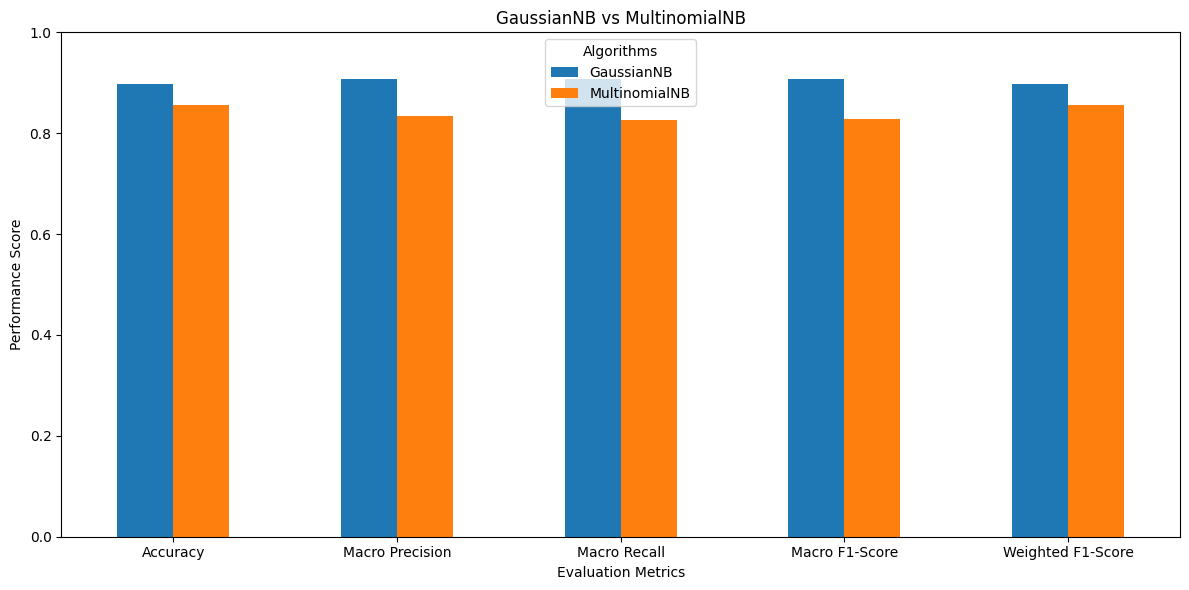

In [60]:
initial_comparison.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("GaussianNB vs MultinomialNB")
plt.ylabel("Performance Score")
plt.xlabel("Evaluation Metrics")
plt.ylim(0, 1)
plt.xticks(rotation=0)

plt.legend(title="Algorithms")
plt.tight_layout()
plt.show()

## 7. Bernoulli Naive Bayes (BernoulliNB)

### 7.1 Introduction

Bernoulli Naive Bayes is a probabilistic classification algorithm based on Bayes' theorem and the Bernoulli probability distribution.

Unlike GaussianNB, which works with continuous numerical features, BernoulliNB is designed for binary-valued features.

It models whether a particular feature is present (1) or absent (0).

In this project, BernoulliNB will be used to classify seven varieties of dry beans using binary representations of their physical and morphological measurements.

### 7.2 Why BernoulliNB?

The original Dry Bean Dataset contains 16 continuous numerical features.

BernoulliNB requires binary feature representations. Therefore, the original numerical measurements must first be converted into binary values.

Median-based binarization will be used as the initial feature transformation technique.

For each feature:

- Values greater than the training median will be represented as 1.
- Values less than or equal to the training median will be represented as 0.

This will preserve all 16 original features while changing their representation into binary values.

### 9.4 Feature Representation

The 16 original numerical features will be converted into binary values using training-set medians.

The resulting features will contain only 0 and 1.

### 9.5 Target Variable

The target variable remains `Class`, containing seven bean varieties:

- BARBUNYA
- BOMBAY
- CALI
- DERMASON
- HOROZ
- SEKER
- SIRA

### 9.6 Model Objective

Train BernoulliNB using binary representations of the original numerical features and evaluate its ability to classify the seven bean varieties.

### Feature Binarization

BernoulliNB is designed for binary-valued input features.

Since the original Dry Bean Dataset contains continuous numerical measurements, feature binarization will be performed.

The median of each feature will be calculated using the training dataset only.

The following transformation will be applied:

- Values greater than the training median will be assigned 1.
- Values less than or equal to the training median will be assigned 0.

This transformation converts the original 16 numerical features into binary representations.

The same training-derived thresholds will be applied to the testing dataset to prevent data leakage.

Median-based binarization provides a simple baseline representation for investigating whether relative feature magnitude can distinguish different bean varieties.

In [61]:
# Calculate feature medians using training data only

feature_medians = X_train.median()

# Binarize training data

X_train_bern = (
    X_train > feature_medians
).astype(int)

# Binarize testing data using training medians

X_test_bern = (
    X_test > feature_medians
).astype(int)

print("Original Training Shape:", X_train.shape)
print("Binary Training Shape:", X_train_bern.shape)

print("\nOriginal Testing Shape:", X_test.shape)
print("Binary Testing Shape:", X_test_bern.shape)

Original Training Shape: (10834, 16)
Binary Training Shape: (10834, 16)

Original Testing Shape: (2709, 16)
Binary Testing Shape: (2709, 16)


In [62]:
display(X_train_bern.head(10))

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
4285,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0
3216,1,1,1,1,0,0,1,1,1,0,0,1,0,0,1,0
7320,1,1,1,1,1,1,1,1,1,1,0,0,0,0,0,0
8034,0,0,0,0,1,1,0,0,1,1,1,0,1,1,0,1
5401,1,1,1,1,1,1,1,1,1,1,0,0,0,0,0,0
13458,0,0,0,0,1,1,0,0,1,1,1,1,1,1,1,1
4090,1,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0
1059,0,0,0,1,0,0,0,0,1,1,1,1,0,1,1,1
10364,0,0,0,0,0,0,0,0,1,0,1,1,1,1,1,0
3966,1,1,1,1,1,1,1,1,0,1,1,0,0,0,0,0


In [63]:
print("Unique Training Values:")
print(np.unique(X_train_bern))

print("\nUnique Testing Values:")
print(np.unique(X_test_bern))

print(
    "\nTraining Contains Only Binary Values:",
    X_train_bern.isin([0, 1]).all().all()
)

print(
    "Testing Contains Only Binary Values:",
    X_test_bern.isin([0, 1]).all().all()
)

Unique Training Values:
[0 1]

Unique Testing Values:
[0 1]

Training Contains Only Binary Values: True
Testing Contains Only Binary Values: True


### Training the BernoulliNB Model

The BernoulliNB classifier will be trained using the binary training features.

During training, the algorithm estimates:

1. Prior probabilities for each bean variety.
2. Probabilities of binary feature presence within each class.
3. Smoothed probability estimates using the alpha parameter.

The trained classifier will use these estimates to predict bean varieties from unseen binary feature observations.

In [65]:
# Create BernoulliNB classifier

bnb = BernoulliNB(
    alpha=1.0,
    binarize=None,
    fit_prior=True,
    force_alpha=True
)

print("BernoulliNB Model Created Successfully!")

BernoulliNB Model Created Successfully!


In [66]:
# Train BernoulliNB

bnb.fit(
    X_train_bern,
    y_train
)

print("BernoulliNB Model Trained Successfully!")

BernoulliNB Model Trained Successfully!


In [67]:
# Make predictions

y_pred_bernoulli = bnb.predict(
    X_test_bern
)

# Display first 10 predictions

bernoulli_predictions = pd.DataFrame({
    "Actual Class": y_test.values[:10],
    "Predicted Class": y_pred_bernoulli[:10]
})

display(bernoulli_predictions)

,Actual Class,Predicted Class
0,SEKER,SEKER
1,DERMASON,DERMASON
2,DERMASON,DERMASON
3,HOROZ,HOROZ
4,SEKER,SEKER
5,DERMASON,DERMASON
6,DERMASON,DERMASON
7,DERMASON,DERMASON
8,BARBUNYA,BARBUNYA
9,DERMASON,DERMASON


In [68]:
# Calculate evaluation metrics

bernoulli_accuracy = accuracy_score(
    y_test,
    y_pred_bernoulli
)

bernoulli_precision = precision_score(
    y_test,
    y_pred_bernoulli,
    average="macro",
    zero_division=0
)

bernoulli_recall = recall_score(
    y_test,
    y_pred_bernoulli,
    average="macro",
    zero_division=0
)

bernoulli_macro_f1 = f1_score(
    y_test,
    y_pred_bernoulli,
    average="macro",
    zero_division=0
)

bernoulli_weighted_f1 = f1_score(
    y_test,
    y_pred_bernoulli,
    average="weighted",
    zero_division=0
)

# Display results

print("Bernoulli Naive Bayes Performance")
print("=" * 45)

print(f"Accuracy:        {bernoulli_accuracy:.4f}")
print(f"Macro Precision: {bernoulli_precision:.4f}")
print(f"Macro Recall:    {bernoulli_recall:.4f}")
print(f"Macro F1-Score:  {bernoulli_macro_f1:.4f}")
print(f"Weighted F1:     {bernoulli_weighted_f1:.4f}")

Bernoulli Naive Bayes Performance
Accuracy:        0.6800
Macro Precision: 0.6654
Macro Recall:    0.6259
Macro F1-Score:  0.6047
Weighted F1:     0.6484


In [69]:
print(
    classification_report(
        y_test,
        y_pred_bernoulli,
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

    BARBUNYA     0.7716    0.4717    0.5855       265
      BOMBAY     0.3766    0.2788    0.3204       104
        CALI     0.4672    0.9816    0.6330       326
    DERMASON     0.7503    0.9661    0.8446       709
       HOROZ     0.7622    0.7151    0.7379       372
       SEKER     0.8414    0.7709    0.8046       406
        SIRA     0.6887    0.1973    0.3068       527

    accuracy                         0.6800      2709
   macro avg     0.6654    0.6259    0.6047      2709
weighted avg     0.7073    0.6800    0.6484      2709



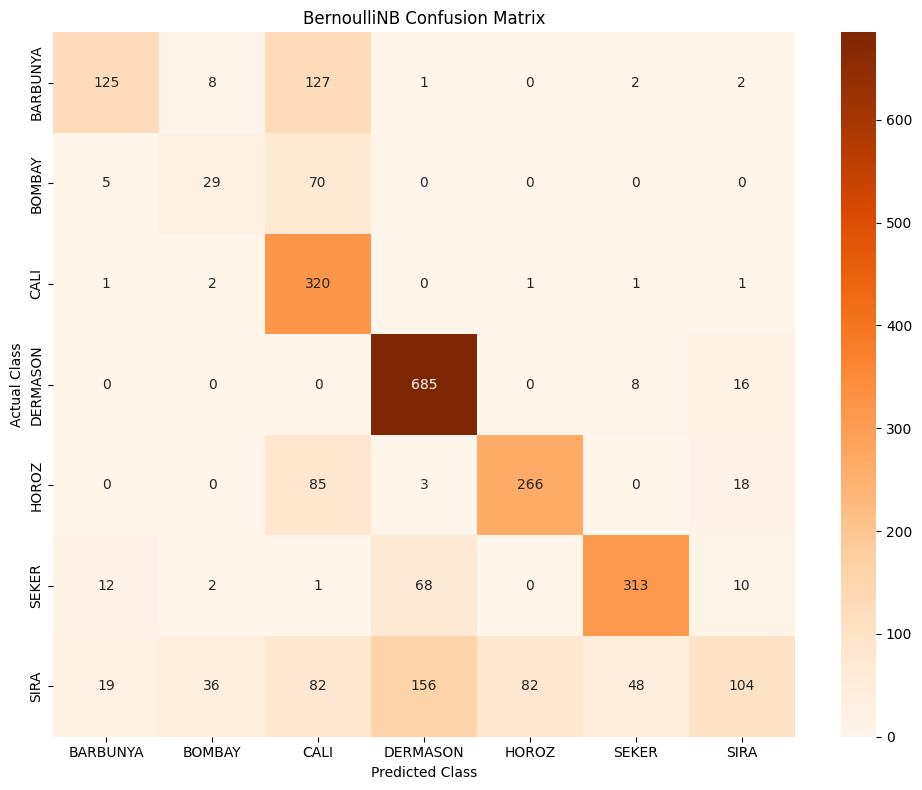

In [71]:
cm_bernoulli = confusion_matrix(
    y_test,
    y_pred_bernoulli,
    labels=bnb.classes_
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_bernoulli,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=bnb.classes_,
    yticklabels=bnb.classes_
)

plt.title("BernoulliNB Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

,precision,recall,f1-score
BARBUNYA,0.7716,0.4717,0.5855
BOMBAY,0.3766,0.2788,0.3204
CALI,0.4672,0.9816,0.6330
DERMASON,0.7503,0.9661,0.8446
HOROZ,0.7622,0.7151,0.7379
SEKER,0.8414,0.7709,0.8046
SIRA,0.6887,0.1973,0.3068


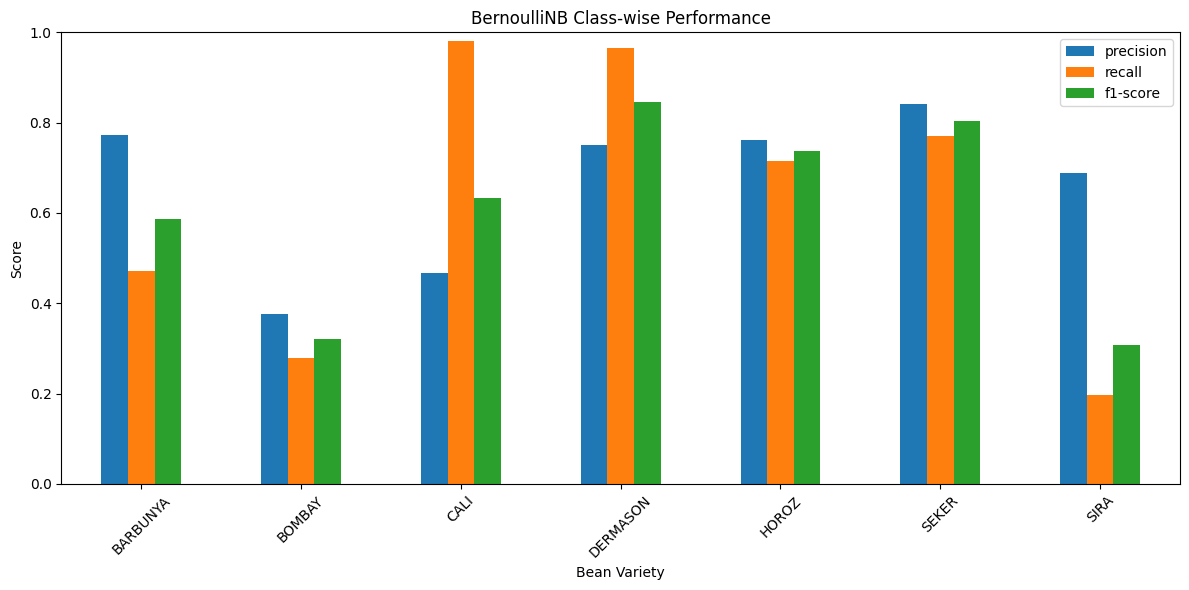

In [73]:
bernoulli_report = classification_report(
    y_test,
    y_pred_bernoulli,
    output_dict=True,
    zero_division=0
)

bernoulli_class_metrics = pd.DataFrame(
    bernoulli_report
).T

bernoulli_class_metrics = bernoulli_class_metrics.loc[
    bnb.classes_,
    ["precision", "recall", "f1-score"]
]

display(bernoulli_class_metrics.round(4))

bernoulli_class_metrics.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("BernoulliNB Class-wise Performance")
plt.xlabel("Bean Variety")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()



### Comparative Analysis of Three Naive Bayes Algorithms

The three Naive Bayes classifiers have been implemented using different feature representations.

- GaussianNB uses the original continuous numerical measurements.
- MultinomialNB uses quantile-discretized and one-hot encoded features.
- BernoulliNB uses median-based binary features.

All three models were trained and evaluated using the same stratified training and testing subsets.

Their classification performance will be compared using accuracy, macro precision, macro recall, macro F1-score, and weighted F1-score.

This comparison will help investigate how different probability distributions and feature representations affect the classification of dry bean varieties.

Macro F1-score will be particularly important when identifying the most balanced classifier across the seven classes.

In [74]:
# Create final comparison dataframe

model_comparison = pd.DataFrame({
    "GaussianNB": [
        gaussian_accuracy,
        gaussian_precision,
        gaussian_recall,
        gaussian_macro_f1,
        gaussian_weighted_f1
    ],

    "MultinomialNB": [
        multinomial_accuracy,
        multinomial_precision,
        multinomial_recall,
        multinomial_macro_f1,
        multinomial_weighted_f1
    ],

    "BernoulliNB": [
        bernoulli_accuracy,
        bernoulli_precision,
        bernoulli_recall,
        bernoulli_macro_f1,
        bernoulli_weighted_f1
    ]

}, index=[
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1-Score",
    "Weighted F1-Score"
])

display(model_comparison.round(4))

,GaussianNB,MultinomialNB,BernoulliNB
Accuracy,0.8970,0.8568,0.6800
Macro Precision,0.9081,0.8334,0.6654
Macro Recall,0.9082,0.8263,0.6259
Macro F1-Score,0.9072,0.8280,0.6047
Weighted F1-Score,0.8972,0.8568,0.6484


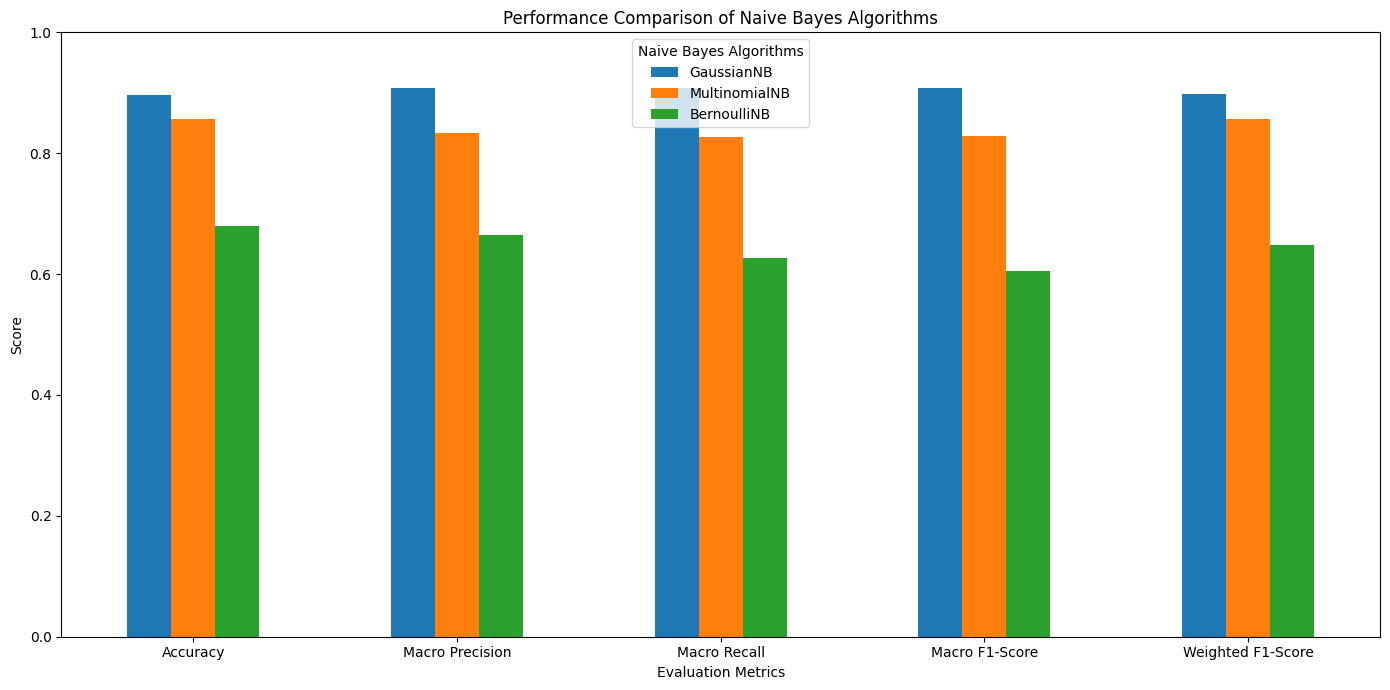

In [75]:
model_comparison.plot(
    kind="bar",
    figsize=(14, 7)
)

plt.title("Performance Comparison of Naive Bayes Algorithms")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.xticks(rotation=0)
plt.legend(title="Naive Bayes Algorithms")

plt.tight_layout()
plt.show()

In [76]:
best_model = model_comparison.loc[
    "Macro F1-Score"
].idxmax()

best_score = model_comparison.loc[
    "Macro F1-Score"
].max()

print("Best Baseline Model:", best_model)
print("Best Macro F1-Score:", round(best_score, 4))

Best Baseline Model: GaussianNB
Best Macro F1-Score: 0.9072
